In [13]:
%load_ext autoreload
%autoreload 2

import os

os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
CKPT_BASE = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/bowl_escape_checkpoints"

CHECKPOINT_PATHS = [
    f"{CKPT_BASE}/260305_121923_943072",
    f"{CKPT_BASE}/260305_121927_185604",
    f"{CKPT_BASE}/260305_121931_486548",
    f"{CKPT_BASE}/260305_122451_201106",
    f"{CKPT_BASE}/260305_122500_320770",
    f"{CKPT_BASE}/260305_122532_946252",
    f"{CKPT_BASE}/260305_122532_946325",
    f"{CKPT_BASE}/260305_122537_170920",
    f"{CKPT_BASE}/260305_122646_222135",
    f"{CKPT_BASE}/260305_122647_297082",
    f"{CKPT_BASE}/260305_122649_833463",
    f"{CKPT_BASE}/260305_123033_896054",
]

EPISODE_LENGTH = 2000  # Rollout steps (matches bowl escape config)
NUM_SEEDS = 20  # Rollout seeds per model

In [15]:
# Run rollouts per model in isolated subprocesses to avoid GPU OOM
# (Warp's CUDA memory pool leaks across iterations within a single process)
# Each subprocess loads one checkpoint and runs NUM_SEEDS rollouts.
import subprocess
import tempfile
from collections import defaultdict
from pathlib import Path

raw_results = []  # List of (mode, distances_array) where distances is (num_seeds, episode_length)

for i, ckpt_path in enumerate(CHECKPOINT_PATHS):
    print(f"[{i + 1}/{len(CHECKPOINT_PATHS)}]")

    with tempfile.NamedTemporaryFile(suffix=".npz", delete=False) as f:
        output_path = f.name

    result = subprocess.run(
        [
            "python", "-m", "scamper.scripts.eval_bowl_escape_single",
            ckpt_path, output_path,
            "--num_seeds", str(NUM_SEEDS),
            "--episode_length", str(EPISODE_LENGTH),
        ],
        cwd="/home/mila/a/aidan.sirbu/SCAMPER",
        capture_output=True,
        text=True,
    )

    # Print subprocess output
    if result.stdout:
        print(result.stdout.rstrip())
    if result.returncode != 0:
        print(f"  FAILED (exit code {result.returncode})")
        if result.stderr:
            stderr_lines = result.stderr.strip().split("\n")
            for line in stderr_lines[-10:]:
                print(f"  {line}")
        continue

    # Load results: distances is (num_seeds, episode_length)
    data = np.load(output_path)
    distances = data["distances"]
    mode = str(data["mode"])
    raw_results.append((mode, distances))
    final_mean = np.mean(distances[:, -1])
    print(f"  Mode: {mode}, {distances.shape[0]} seeds, mean final distance: {final_mean:.3f} m")
    os.unlink(output_path)
    print()

# Group by mode: each entry in grouped[mode] is one seed's distance array
grouped = defaultdict(list)
for mode, distances in raw_results:
    for seed_distances in distances:
        grouped[mode].append(seed_distances)

print("Summary:")
for mode in sorted(grouped):
    n = len(grouped[mode])
    final_dists = [d[-1] for d in grouped[mode]]
    print(f"  {mode}: n={n}, final distance = {np.mean(final_dists):.3f} +/- {np.std(final_dists):.3f} m")

[1/12]


KeyboardInterrupt: 

In [ ]:
# Save rollout results for reuse without re-running rollouts
import pandas as pd
from pathlib import Path

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/bowl_escape_analysis")
save_dir.mkdir(parents=True, exist_ok=True)

# Save as a long-format CSV: checkpoint_idx, seed, mode, timestep, distance
rows = []
rollout_idx = 0
for ckpt_idx, (mode, distances) in enumerate(raw_results):
    for seed in range(distances.shape[0]):
        for t, d in enumerate(distances[seed]):
            rows.append({
                "rollout_idx": rollout_idx,
                "checkpoint_idx": ckpt_idx,
                "seed": seed,
                "mode": mode,
                "timestep": t,
                "distance": d,
            })
        rollout_idx += 1

df_results = pd.DataFrame(rows)
csv_path = save_dir / "bowl_escape_distance_rollouts.csv"
df_results.to_csv(csv_path, index=False)
print(f"Saved {len(df_results)} rows ({rollout_idx} rollouts) to {csv_path}")
df_results.head()

In [ ]:
# Load rollout results from CSV (skip cells 0-5 if data already saved)
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict

csv_path = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/bowl_escape_analysis/bowl_escape_distance_rollouts.csv")
df_loaded = pd.read_csv(csv_path)

# Reconstruct grouped dict: mode -> list of distance arrays
grouped = defaultdict(list)
for rollout_idx in df_loaded["rollout_idx"].unique():
    rollout_df = df_loaded[df_loaded["rollout_idx"] == rollout_idx].sort_values("timestep")
    mode = rollout_df["mode"].iloc[0]
    grouped[mode].append(rollout_df["distance"].values)

n_rollouts = len(df_loaded["rollout_idx"].unique())
print(f"Loaded {n_rollouts} rollouts from {csv_path}")
print(f"Modes: {sorted(grouped.keys())}")
for mode in sorted(grouped):
    print(f"  {mode}: n={len(grouped[mode])}")

In [10]:
# Compute escape times from distance data
BOWL_HSIZE = 2.0

MODE_LABELS = {
    "scratch": "Scratch",
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
}
MODE_ORDER = ["scratch", "prior_decoder", "decoder_only"]
modes_with_data = [m for m in MODE_ORDER if m in grouped]

# escape_times: dict mode -> list of escape timesteps (None if never escaped)
escape_times = {}
for mode in modes_with_data:
    times = []
    for dists in grouped[mode]:
        crossed = np.where(dists >= BOWL_HSIZE)[0]
        times.append(int(crossed[0]) if len(crossed) > 0 else None)
    escape_times[mode] = times

# Print summary
for mode in modes_with_data:
    times = escape_times[mode]
    escaped = [t for t in times if t is not None]
    n_escaped = len(escaped)
    n_total = len(times)
    if escaped:
        print(f"{MODE_LABELS[mode]}: {n_escaped}/{n_total} escaped, "
              f"mean time = {np.mean(escaped):.0f} +/- {np.std(escaped):.0f} steps")
    else:
        print(f"{MODE_LABELS[mode]}: {n_escaped}/{n_total} escaped")

Scratch: 4/4 escaped, mean time = 79 +/- 9 steps
Prior-Enabled: 4/4 escaped, mean time = 389 +/- 47 steps
Decoder-Only: 4/4 escaped, mean time = 1282 +/- 304 steps


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/bowl_escape_survival.[pdf|svg|png]


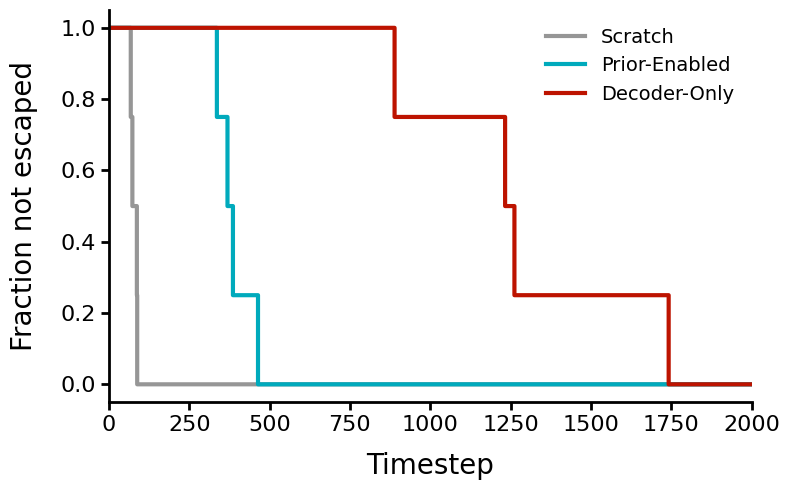

In [12]:
# Survival curve: fraction of rollouts that have NOT yet escaped vs timestep
import seaborn as sns

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)

palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

episode_length = len(grouped[modes_with_data[0]][0])
timesteps = np.arange(episode_length)

fig, ax = plt.subplots(figsize=(8, 5))

for mode in modes_with_data:
    label = MODE_LABELS[mode]
    n = len(escape_times[mode])
    # For each timestep, count how many rollouts have NOT escaped yet
    # A rollout with escape_time=None never escapes (stays in "not escaped" for all t)
    not_escaped = np.ones(episode_length)
    for t_esc in escape_times[mode]:
        if t_esc is not None:
            not_escaped[t_esc:] -= 1.0 / n
    ax.step(timesteps, not_escaped, where="post", color=palette[label], linewidth=3, label=label)

ax.set_xlabel("Timestep", fontsize=20, labelpad=12)
ax.set_ylabel("Fraction not escaped", fontsize=20, labelpad=16)
ax.set_ylim(-0.05, 1.05)
ax.set_xlim(0, episode_length)
ax.tick_params(labelsize=16, width=2, length=6)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.legend(fontsize=14, frameon=False, loc="upper right")

plt.tight_layout()

save_name = "bowl_escape_survival"
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()